In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("/content/train.csv", on_bad_lines='skip')
df.head()

,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,...,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds
0,6901257,5.010635,Apartment,Entire home/apt,"{""Wireless Internet"",""Air conditioning"",Kitche...",3,1.0,Real Bed,strict,True,...,40.696524,-73.991617,Beautiful brownstone 1-bedroom,Brooklyn Heights,2,100.0,https://a0.muscache.com/im/pictures/6d7cbbf7-c...,11201,1.0,1.0
1,6304928,5.129899,Apartment,Entire home/apt,"{""Wireless Internet"",""Air conditioning"",Kitche...",7,1.0,Real Bed,strict,True,...,40.766115,-73.989040,Superb 3BR Apt Located Near Times Square,Hell's Kitchen,6,93.0,https://a0.muscache.com/im/pictures/348a55fe-4...,10019,3.0,3.0
2,7919400,4.976734,Apartment,Entire home/apt,"{TV,""Cable TV"",""Wireless Internet"",""Air condit...",5,1.0,Real Bed,moderate,True,...,40.808110,-73.943756,The Garden Oasis,Harlem,10,92.0,https://a0.muscache.com/im/pictures/6fae5362-9...,10027,1.0,3.0
3,13418779,6.620073,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,flexible,True,...,37.772004,-122.431619,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.0,2.0
4,3808709,4.744932,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.0,Real Bed,moderate,True,...,38.925627,-77.034596,Great studio in midtown DC,Columbia Heights,4,40.0,NaN,20009,0.0,1.0


In [4]:
df.shape

(74111, 29)

In [5]:
df.columns.tolist()

['id',
 'log_price',
 'property_type',
 'room_type',
 'amenities',
 'accommodates',
 'bathrooms',
 'bed_type',
 'cancellation_policy',
 'cleaning_fee',
 'city',
 'description',
 'first_review',
 'host_has_profile_pic',
 'host_identity_verified',
 'host_response_rate',
 'host_since',
 'instant_bookable',
 'last_review',
 'latitude',
 'longitude',
 'name',
 'neighbourhood',
 'number_of_reviews',
 'review_scores_rating',
 'thumbnail_url',
 'zipcode',
 'bedrooms',
 'beds']

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74111 entries, 0 to 74110
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      74111 non-null  int64  
 1   log_price               74111 non-null  float64
 2   property_type           74111 non-null  object 
 3   room_type               74111 non-null  object 
 4   amenities               74111 non-null  object 
 5   accommodates            74111 non-null  int64  
 6   bathrooms               73911 non-null  float64
 7   bed_type                74111 non-null  object 
 8   cancellation_policy     74111 non-null  object 
 9   cleaning_fee            74111 non-null  bool   
 10  city                    74111 non-null  object 
 11  description             74111 non-null  object 
 12  first_review            58247 non-null  object 
 13  host_has_profile_pic    73923 non-null  object 
 14  host_identity_verified  73923 non-null

In [7]:
df.describe()

,id,log_price,accommodates,bathrooms,latitude,longitude,number_of_reviews,review_scores_rating,bedrooms,beds
count,7.411100e+04,74111.000000,74111.000000,73911.000000,74111.000000,74111.000000,74111.000000,57389.000000,74020.000000,73980.000000
mean,1.126662e+07,4.782069,3.155146,1.235263,38.445958,-92.397525,20.900568,94.067365,1.265793,1.710868
std,6.081735e+06,0.717394,2.153589,0.582044,3.080167,21.705322,37.828641,7.836556,0.852143,1.254142
min,3.440000e+02,0.000000,1.000000,0.000000,33.338905,-122.511500,0.000000,20.000000,0.000000,0.000000
25%,6.261964e+06,4.317488,2.000000,1.000000,34.127908,-118.342374,1.000000,92.000000,1.000000,1.000000
50%,1.225415e+07,4.709530,2.000000,1.000000,40.662138,-76.996965,6.000000,96.000000,1.000000,1.000000
75%,1.640226e+07,5.220356,4.000000,1.000000,40.746096,-73.954660,23.000000,100.000000,1.000000,2.000000
max,2.123090e+07,7.600402,16.000000,8.000000,42.390437,-70.985047,605.000000,100.000000,10.000000,18.000000


In [8]:
print(df.isnull().sum().sort_values(ascending = False).head(29))

host_response_rate        18299
review_scores_rating      16722
first_review              15864
last_review               15827
thumbnail_url              8216
neighbourhood              6872
zipcode                     966
bathrooms                   200
host_identity_verified      188
host_has_profile_pic        188
host_since                  188
beds                        131
bedrooms                     91
description                   0
city                          0
cleaning_fee                  0
cancellation_policy           0
accommodates                  0
bed_type                      0
room_type                     0
amenities                     0
id                            0
log_price                     0
property_type                 0
instant_bookable              0
longitude                     0
latitude                      0
number_of_reviews             0
name                          0
dtype: int64


In [9]:
print("Duplicate raws:" , df.duplicated().sum())

Duplicate raws: 0


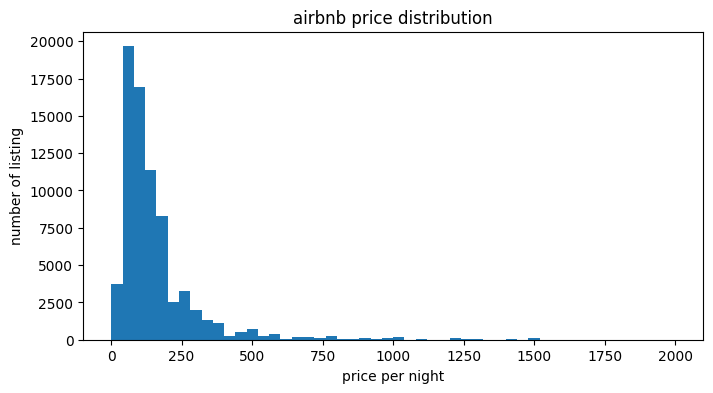

In [10]:

df["price"] = np.exp(df["log_price"])

valid_price = df.loc[df["price"] > 0, "price"]
plt.figure(figsize=(8, 4))
plt.hist(valid_price, bins=50)
plt.title("airbnb price distribution")
plt.xlabel("price per night")
plt.ylabel("number of listing")
plt.show()

In [11]:
df = df.dropna(subset = ["price"])

In [12]:
df = df[df["price"] >0].copy()

In [13]:
df = df.drop_duplicates()

In [14]:
print("clean dataset shape:" , df.shape)

clean dataset shape: (74111, 30)


In [15]:
candidate_features = [
    "room_type" ,
    "property_type" ,
    "accommodates",
    "bedrooms",
    "bathrooms",
    "beds",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "review_scores_rating",
    "latitude",
    "longitude",
    "availability_365",
    "host_is_superhost",
    "neighbourhood_cleansed",
    "neighbourhood_group",
    "city"
]

features = [col for col in candidate_features if col in df.columns]

x = df[features].copy()
y = df["price"].copy()

print("selected features:" , features)
print("numbers of features:" , len(features))

selected features: ['room_type', 'property_type', 'accommodates', 'bedrooms', 'bathrooms', 'beds', 'number_of_reviews', 'review_scores_rating', 'latitude', 'longitude', 'city']
numbers of features: 11


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# Corrected variable name
numeric_features = x.select_dtypes(
    include = ["number" , "bool"]
).columns.tolist()

# Corrected categorical column extraction
categorical_features = x.select_dtypes(
    exclude = ["number", "bool"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [17]:
x_train , x_test , y_train , y_test = train_test_split(
    x ,
    y ,
    test_size = 0.2 ,
    random_state = 42
)

print("training rows:" , len(x_train))
print("testing rows:" , len(x_test))

training rows: 59288
testing rows: 14823


In [18]:
from sklearn.pipeline import Pipeline

model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", model)
])

# Corrected X_train to x_train
pipeline.fit(x_train, y_train)

print("Model training complete!")

Model training complete!


In [19]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Test data par prediction
y_pred = pipeline.predict(x_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

MAE: 55.04
RMSE: 117.50
R2 Score: 0.5286


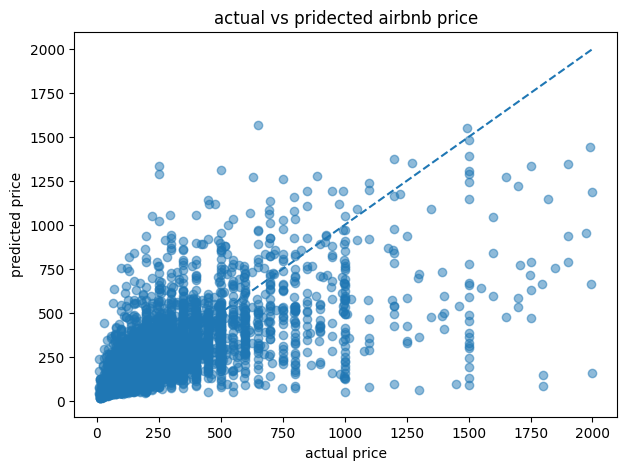

In [24]:
plt.figure(figsize = (7 , 5))
plt.scatter(y_test , y_pred , alpha = 0.5)
low = min(y_test.min() , y_pred.min())
high = max(y_test.max() , y_pred.max())
plt.plot([low , high] , [low , high] , linestyle = "--")
plt.xlabel("actual price")
plt.ylabel("predicted price")
plt.title("actual vs pridected airbnb price")
plt.show()

In [26]:
new_property = x.iloc[[0]].copy()
example_values = {
    "room_type": "Entire home/apt",
    "property_type": "Apartment",
    "accommodates": 4,
    "bedrooms": 2,
    "bathrooms": 1,
    "beds": 2,
    "minimum_nights": 2,
    "number_of_reviews": 50,
    "reviews_per_month": 2.0,
    "review_scores_rating": 95.0,
    "availability_365": 180
}
for col, value in example_values.items():
    if col in new_property.columns:
        new_property.loc[:, col] = value

predicted_price = pipeline.predict(new_property)[0]
print(f"Predicted nightly price: {predicted_price:.2f}")

Predicted nightly price: 191.38


In [27]:
import joblib

joblib.dump(pipeline, "airbnb_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [28]:
loaded_model = joblib.load("airbnb_price_model.pkl")

prediction = loaded_model.predict(new_property)

print("Predicted price:", round(prediction[0], 2))


Predicted price: 191.38
